# TUGAS 2 – VERIFIKASI PYTHON
## Praktikum Data Mining
Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.
### Evaluasi Model Klasifikasi

**Tujuan Praktikum**

Melakukan verifikasi hasil evaluasi model klasifikasi menggunakan
perhitungan manual dan library Scikit-learn berdasarkan nilai
Confusion Matrix.

## 4.1 Menyiapkan Dataset Sintetis

Dataset yang digunakan merupakan data sintetis transaksi pembayaran
digital sebanyak 500 data. Dataset terdiri dari fitur nominal
transaksi, jam transaksi, perangkat baru, IP luar negeri, dan label
isFraud. Label 0 menunjukkan transaksi normal, sedangkan label 1
menunjukkan transaksi fraud.

In [25]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500

amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)

prob = 1/(1+np.exp(-score))

isFraud = rng.binomial(1, prob)

df = pd.DataFrame({
    'amount':amount.round(2), 'hour':hour,
    'new_device':new_device, 'foreign_ip':foreign_ip,
    'isFraud':isFraud
})

print(df.head())

print('Distribusi kelas:')
print(df['isFraud'].value_counts())

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


Output yang dihasilkan berupa lima baris awal dataset dan jumlah
transaksi pada masing-masing kelas. Dataset ini selanjutnya digunakan
dalam proses pelatihan dan pengujian model klasifikasi.

### 4.2 Membagi Data dan Melatih Model

Dataset dibagi menjadi data latih dan data uji menggunakan
train_test_split dengan proporsi 70% data latih dan 30% data uji.
Selanjutnya, model Decision Tree dilatih menggunakan data latih
untuk menghasilkan prediksi pada data uji.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Data uji:', len(y_test))

Data uji: 150


In [14]:
df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

print(df.head())

print('Distribusi kelas:')
print(df['isFraud'].value_counts())

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


Output menunjukkan jumlah data uji sebanyak 150 data. Pembagian
data menggunakan stratify=y untuk menjaga proporsi kelas pada
data latih dan data uji. Parameter class_weight='balanced'
digunakan untuk menyesuaikan bobot kelas berdasarkan distribusi data.

### 4.3 Menghitung Confusion Matrix

Confusion Matrix digunakan untuk membandingkan label aktual dengan
hasil prediksi model. Hasil perbandingan digunakan untuk memperoleh
nilai True Positive (TP), True Negative (TN), False Positive (FP),
dan False Negative (FN).

In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()

print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


Output berupa Confusion Matrix dan empat komponen evaluasi.
Nilai TP menunjukkan transaksi fraud yang benar terdeteksi,
TN menunjukkan transaksi normal yang benar dikenali, FP
menunjukkan transaksi normal yang salah ditandai sebagai fraud,
sedangkan FN menunjukkan transaksi fraud yang tidak terdeteksi.

Keempat nilai tersebut digunakan sebagai dasar perhitungan
metrik evaluasi pada tahap berikutnya.

### 4.4 Perhitungan Manual dan Verifikasi

Perhitungan manual dilakukan berdasarkan nilai TP, TN, FP, dan FN
yang diperoleh dari Confusion Matrix. Metrik yang dihitung meliputi
Accuracy, Precision, Recall, dan F1-Score. Selanjutnya, hasil
perhitungan manual dibandingkan dengan hasil evaluasi menggunakan
fungsi Scikit-learn.

In [29]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

precision = tp / (tp + fp) if tp + fp else 0

recall = tp / (tp + fn) if tp + fn else 0

f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(
    accuracy_score(y_test,y_pred),
    precision_score(y_test,y_pred,zero_division=0),
    recall_score(y_test,y_pred,zero_division=0),
    f1_score(y_test,y_pred,zero_division=0)
)

0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


Hasil perhitungan manual dibandingkan dengan hasil evaluasi
menggunakan Scikit-learn. Perbandingan dilakukan untuk mengetahui
kesesuaian nilai Accuracy, Precision, Recall, dan F1-Score yang
diperoleh melalui kedua metode perhitungan.

Kedua hasil seharusnya sama, selain perbedaan pembulatan tampilan.

### 4.5 Visualisasi Confusion Matrix

Visualisasi Confusion Matrix dilakukan untuk menampilkan hasil
klasifikasi model dalam bentuk grafik. Visualisasi ini membantu
mengidentifikasi jumlah prediksi yang benar maupun kesalahan
klasifikasi pada transaksi normal dan fraud. sklearn.metrics import confusion_matrix

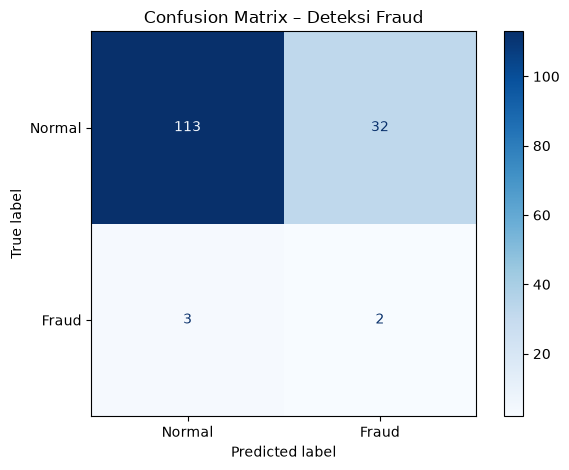

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

Gambar 1. Confusion Matrix Model Decision Tree pada Data Uji.

Visualisasi menunjukkan hasil klasifikasi berdasarkan empat
komponen Confusion Matrix. False Negative (FN) menunjukkan
transaksi fraud yang tidak terdeteksi sehingga berpotensi
menimbulkan kerugian. Sementara itu, False Positive (FP)
menunjukkan transaksi normal yang salah ditandai sebagai fraud
sehingga dapat mengganggu pelanggan.

### 4.6 Interpretasi dan Studi Kasus 
Dalam deteksi fraud, FN berarti transaksi fraud tidak terdeteksi dan berpotensi menimbulkan kerugian; FP berarti transaksi normal ditandai fraud dan dapat mengganggu pelanggan. Recall tinggi membantu mengurangi fraud yang lolos, tetapi dapat meningkatkan alarm palsu. Pilihan metrik perlu mempertimbangkan biaya masing-masing kesalahan.

### 4.7 Eksperimen: Baseline Semua Normal

In [32]:
baseline = np.zeros(len(y_test), dtype=int) 
from sklearn.metrics import classification_report 
print('Baseline accuracy:', accuracy_score(y_test, baseline)) 
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0)) 
print('Decision Tree:') 
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



### 4.8 Eksperimen: Pengaruh Ambang Prediksi

In [33]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)] 
for threshold in [0.2, 0.4, 0.5, 0.7]: 
    pred = (y_prob >= threshold).astype(int) 
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3), 
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))

0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2


### Kesimpulan

Berdasarkan praktikum yang telah dilakukan, model Decision Tree
berhasil dilatih dan digunakan untuk melakukan klasifikasi
transaksi pembayaran digital. Evaluasi dilakukan menggunakan
Confusion Matrix untuk memperoleh nilai TP, TN, FP, dan FN.

Nilai tersebut selanjutnya digunakan untuk menghitung Accuracy,
Precision, Recall, dan F1-Score secara manual serta dibandingkan
dengan hasil perhitungan menggunakan Scikit-learn. Hasil
perbandingan digunakan untuk memverifikasi kesesuaian kedua
metode perhitungan. Selain itu, visualisasi Confusion Matrix
digunakan untuk mengidentifikasi kesalahan prediksi model.